this script calculates the author distribution using income group motif

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from random import sample
from itertools import permutations

In [2]:
author_path="../../data/dropbox/LaborDivision/Data/deriveddata/pubs_noalpha_int/authors_o.pkl"
pub_path="../../data/dropbox/LaborDivision/Data/deriveddata/pubs_noalpha_int/pubs_noalpha_int.pkl"
ingroup_path = '../../data/dropbox/LaborDivision/Data/additionaldata/cntry_meta.csv'

In [3]:
author_df=pd.read_pickle(author_path)

FileNotFoundError: [Errno 2] No such file or directory: '../../data/dropbox/LaborDivision/Data/deriveddata/pubs_noalpha_int/authors_o.pkl'

In [4]:
pub_df=pd.read_pickle(pub_path)

In [5]:
ingroup_df=pd.read_csv(ingroup_path)
ingroupdict = dict(zip(ingroup_df['Code'],ingroup_df['ingroup_08-20']))

In [6]:
author_df['ingroup']=author_df['Code'].map(ingroupdict)

In [7]:
incomes=['H','UM','LM',"L"]
keys = []
for a in permutations(incomes,2):
    keys.append('_'.join(a))
for a in permutations(incomes,3):
    keys.append('_'.join(a))

In [8]:
values1=['H_UM','H_LM','H_L','H_UM','UM_LM','UM_L','H_LM','UM_LM','LM_L','H_L','UM_L','LM_L']      

In [9]:
values2 = ['H_UM_LM', 'H_UM_L','H_UM_LM','H_LM_L','H_UM_L','H_LM_L','H_UM_LM','H_UM_L','H_UM_LM','UM_LM_L',
          'H_UM_L','UM_LM_L','H_UM_LM','H_LM_L','H_UM_LM','UM_LM_L','H_LM_L','UM_LM_L','H_UM_L','H_LM_L',
          'H_UM_L','UM_LM_L','H_LM_L','UM_LM_L']
values=values1+values2

In [10]:
motif_dict=dict(zip(keys,values))

In [11]:
author_df.shape

(29821778, 12)

In [12]:
motif= author_df.groupby(['id'])['ingroup'].apply(list).reset_index()

In [13]:
motif['group_distinct']=motif['ingroup'].apply(lambda x:list(set(x)))

In [14]:
def assign_motif(groups):
    if len(groups)==1:
        return groups[0]
    elif len(groups)==4:
        return 'H_UM_LM_L'
    else:
        k='_'.join(groups)
        return motif_dict[k]
motif['motif']=motif['group_distinct'].apply(lambda x:assign_motif(x))

In [19]:
cnt_df = motif.groupby('motif').size().sort_values(ascending=False).reset_index(name='count')

In [20]:
cnt_df['p']=cnt_df['count']/cnt_df['count'].sum()

In [21]:
cnt_df

,motif,count,p
0,H,1823277,0.520527
1,H_UM,1176380,0.335844
2,H_LM,276773,0.079016
3,UM_LM,55188,0.015756
4,UM,52872,0.015094
5,H_UM_LM,52685,0.015041
6,H_L,38833,0.011086
7,H_LM_L,6531,0.001865
8,LM,5312,0.001517
9,H_UM_L,4350,0.001242


In [22]:
cnt_df = cnt_df[~cnt_df.motif.isin(['H','UM','LM','L'])]

In [23]:
def norm(df):
    df = df.groupby(['year','ingroup']).size(
    ).reset_index(name='count'
                 ).pivot(index='year',columns='ingroup',values='count')
    df=df.div(df.sum(axis=1), axis=0).reset_index()
    df = df.melt(id_vars='year', var_name='ingroup', value_name='count')
    return df

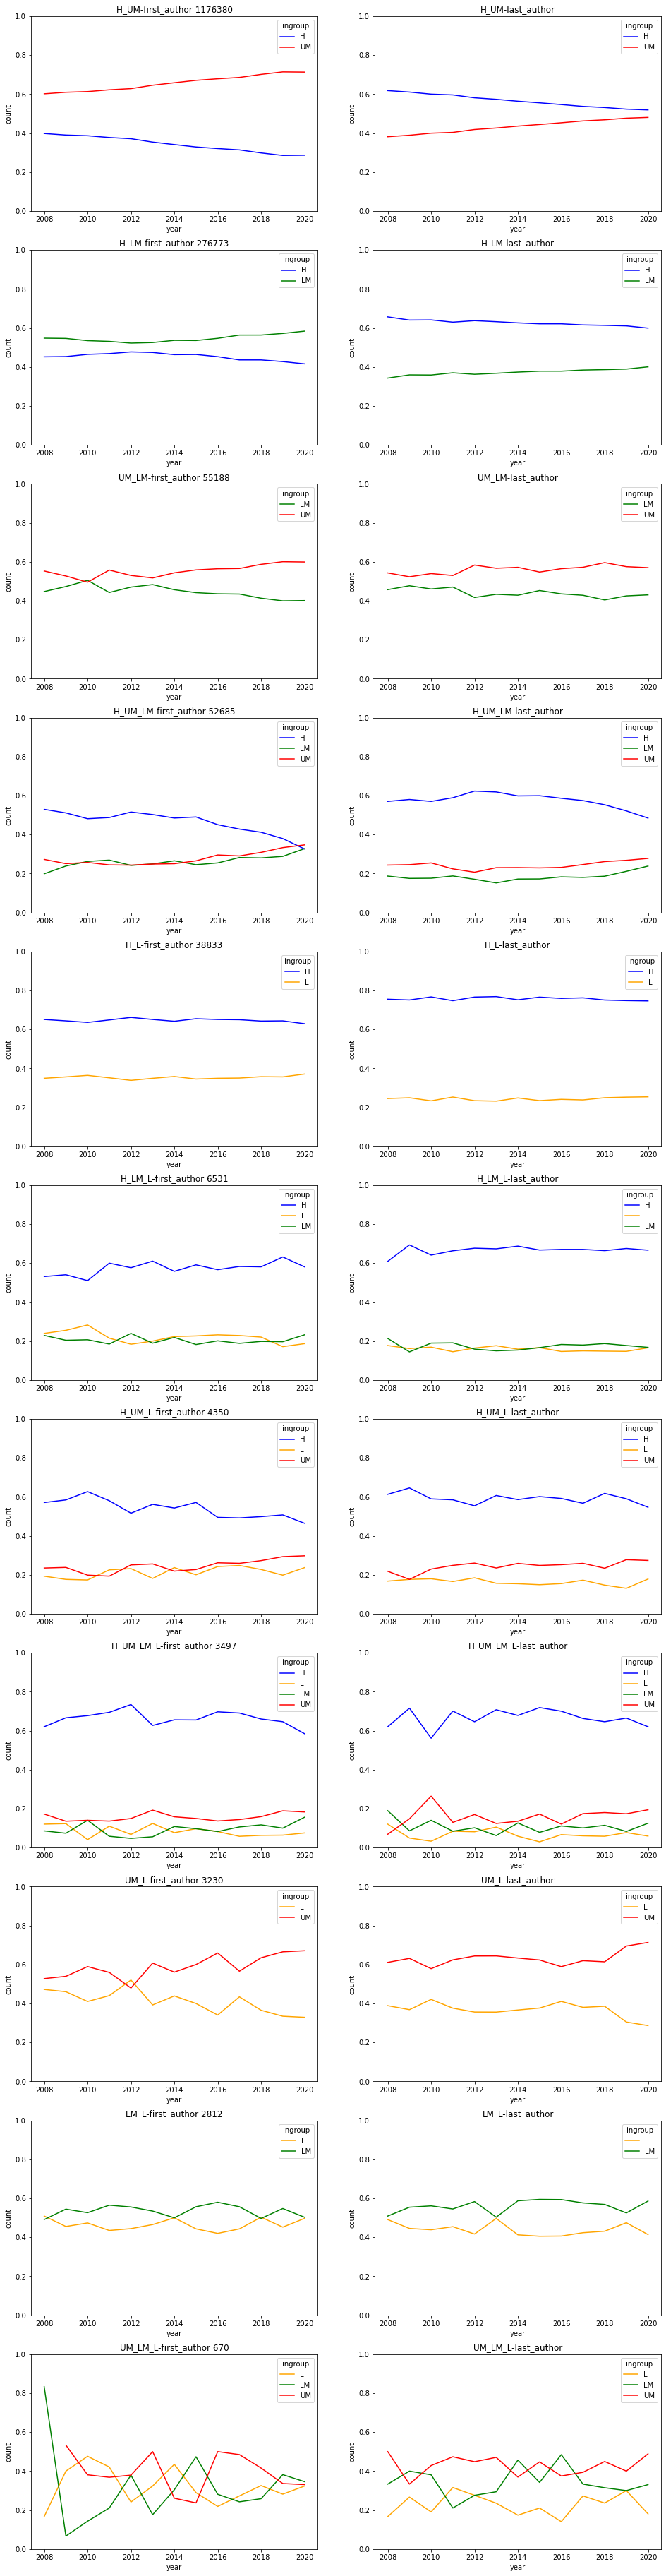

In [24]:
gs = cnt_df.motif.values
fig, ax = plt.subplots(nrows=11,ncols=2,figsize=(16,66))
cdict={'H':'blue','L':'orange','LM':'green','UM':'red'}
for index, g in enumerate(gs):
    gin = motif[motif['motif']==g]['id'].unique()
    gdf=author_df[author_df['id'].isin(gin)]
    
    first_df=gdf[gdf.role=='F']
    first_df=norm(first_df)
    sns.lineplot(x='year',y='count',hue='ingroup',data=first_df,ax=ax[index][0],palette=cdict)
    ax[index][0].set_ylim(0,1)
    ax[index][0].set_title("{}-{} {}".format(g,'first_author',cnt_df[cnt_df.motif==g]['count'].values[0]))
    
    
    last_df=gdf[gdf.role=='L']
    last_df=norm(last_df)
    sns.lineplot(x='year',y='count',hue='ingroup',data=last_df,ax=ax[index][1],palette=cdict)
    ax[index][1].set_ylim(0,1)
    ax[index][1].set_title("{}-{}".format(g,'last_author'))


In [25]:
ids = motif[motif['motif']=='H_LM']['id']

In [27]:
tt = author_df[author_df['id'].isin(ids)]

In [31]:
tt[tt.role=='F'].groupby('Code').size().sort_values(ascending=False).head(10)

Code
IND    64121
USA    27985
PAK    16328
TUN    13399
EGY    12102
FRA     9986
SAU     9727
GBR     9408
JPN     8684
DEU     8373
dtype: int64